# Semana 5 — Programación dinámica, retroceso, módulos y pandas aplicado a Penonomé

Aplica las unidades 32 a 36 del curso: [programación dinámica](../../../../01-python/semana-05/clase-1-programacion-dinamica-y-backtracking/u32-programacion-dinamica.ipynb), [retroceso](../../../../01-python/semana-05/clase-1-programacion-dinamica-y-backtracking/u33-backtracking.ipynb), [módulos de Python](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u34-modulos-de-python.ipynb), [Series de pandas](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u35-series-de-pandas.ipynb) y [DataFrames de pandas](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u36-dataframes-de-pandas.ipynb).

[Proyecto](../../README.md) | [Anterior](s04-ordenamiento-greedy-divide-y-venceras.ipynb) | [Siguiente](s06-ordenacion-series-temporales.ipynb)

In [1]:
def verificar(descripcion, obtenido, esperado):
    """Compara el resultado de un ejercicio con el esperado e informa sin detener el notebook."""
    if obtenido == esperado:
        print(f"Correcto: {descripcion}")
    else:
        print(f"Incorrecto: {descripcion}. Se esperaba {esperado!r} y se obtuvo {obtenido!r}")

## Qué hace este notebook

Hasta la semana 4 el proyecto leía los CSV con el módulo `csv` y trabajaba con listas y diccionarios (`penonome.carga` y `penonome.modelos`). Desde aquí los datos se cargan con pandas y las funciones nuevas viven en un módulo propio, `penonome.analisis`, que también usa el notebook de la semana 6.

| Sección | Unidad | Datos |
|---|---|---|
| 1. Módulos y paquetes | u34 | paquete `penonome` |
| 2. Series | u35 | población por corregimiento (Censo 2023, tabla 01) |
| 3. DataFrames | u36 | Encuesta de Mercado Laboral (tabla 03) y Censo 2023 (tabla 02) |
| 4. Programación dinámica | u32 | PIB de Coclé (tabla 10) y escenarios de desempleo (`datos/comparacion-colombia/30`) |
| 5. Retroceso | u33 | población por corregimiento (tabla 01) |

Todas las cifras son oficiales (INEC, ATP, DANE) salvo donde se indica que se trata de un modelo o de un supuesto.

## 1. Módulos y paquetes: `penonome.analisis`

En la [Unidad 34](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u34-modulos-de-python.ipynb) un módulo es un archivo `.py` que se importa por su nombre sin la extensión, y se usa con la forma `modulo.funcion()`. El proyecto aplica la misma idea a mayor escala: `src/penonome/` es un **paquete**, una carpeta de módulos, y cada semana agrega uno.

| Módulo | Semana | Qué contiene |
|---|---|---|
| `penonome/__init__.py` | todas | las rutas `RAIZ`, `PAQUETE` y `COMPARACION` |
| `penonome/carga.py` | 1 y 2 | lectura de los CSV con el módulo `csv` |
| `penonome/modelos.py` | 2 | las clases `Corregimiento` y `Fuente` |
| `penonome/estructuras.py` y `penonome/busqueda.py` | 3 | pilas, colas, tablas hash y búsquedas |
| `penonome/ordenamiento.py` | 4 | algoritmos de ordenamiento |
| `penonome/analisis.py` | 5 y 6 | pandas, programación dinámica y retroceso |

**Ampliación (no está en el PDF):** el archivo `__init__.py` convierte la carpeta en paquete y se ejecuta la primera vez que se importa `penonome`; por eso las rutas se definen ahí una sola vez y los demás módulos las importan con `from penonome import PAQUETE`. El ambiente de uv instala el paquete en modo editable, así que un cambio en `analisis.py` se ve al reiniciar el kernel sin reinstalar nada.

In [2]:
import sys
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd

import penonome                          # el paquete: ejecuta penonome/__init__.py
import penonome.analisis as an           # la sentencia as de la u34
from penonome.analisis import leer       # la sentencia from de la u34

print("Paquete :", penonome.__name__, "->", penonome.__file__.split("src/")[-1])
print("Módulo  :", an.__name__, "->", an.__file__.split("src/")[-1])
print("Datos   :", penonome.PAQUETE.name, "y", penonome.COMPARACION.name)
print("Funciones públicas de analisis:")
print([nombre for nombre in dir(an) if not nombre.startswith("_") and callable(getattr(an, nombre))])

Paquete : penonome -> penonome/__init__.py
Módulo  : penonome.analisis -> penonome/analisis.py
Datos   : penonome y comparacion-colombia
Funciones públicas de analisis:
['a_ancho', 'a_largo', 'base_larga', 'brecha_colombia', 'combinaciones_minimas', 'eml_tidy', 'estilo_eje', 'golpe_restante', 'indice_base_100', 'leer', 'maximum_subarray', 'ordenar_larga', 'pib_anual', 'poblacion_corregimientos', 'proyectar_desempleo', 'replicas', 'variacion_pct', 'visitantes_mensuales']


In [3]:
# Un módulo se carga una sola vez: las dos formas de importar apuntan al mismo objeto
verificar("el módulo quedó registrado en sys.modules", "penonome.analisis" in sys.modules, True)
verificar("from ... import trae la misma función", leer is an.leer, True)
verificar("analisis usa las rutas del __init__ del paquete", an.PAQUETE == penonome.PAQUETE, True)

Correcto: el módulo quedó registrado en sys.modules
Correcto: from ... import trae la misma función
Correcto: analisis usa las rutas del __init__ del paquete


El módulo `datetime` de la [Unidad 34](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u34-modulos-de-python.ipynb) sirve para fechar el proyecto: el terremoto de Penonomé fue el 9 de octubre de 2026 y el último dato de seguimiento del estudio es del 21 de noviembre de 2026. La EML de agosto de 2026 es el último dato de desempleo anterior al sismo.

In [4]:
sismo = date(2026, 10, 9)
ultimo_seguimiento = date(2026, 11, 21)
eml_previa = date(2026, 8, 1)

dias = ultimo_seguimiento - sismo                 # restar fechas da un timedelta
print(type(dias).__name__, "->", dias.days, "días de seguimiento")
print("Una semana después del sismo:", (sismo + timedelta(weeks=1)).strftime("%d/%m/%Y"))
print("Meses entre la EML de agosto y el sismo:", (sismo.year - eml_previa.year) * 12 + sismo.month - eml_previa.month)

verificar("días entre el sismo y el último seguimiento", dias.days, 43)

timedelta -> 43 días de seguimiento
Una semana después del sismo: 16/10/2026
Meses entre la EML de agosto y el sismo: 2
Correcto: días entre el sismo y el último seguimiento


**Error común:** ejecutar un notebook con un Python distinto del ambiente del proyecto y obtener `ModuleNotFoundError: No module named 'penonome'`. El paquete solo existe dentro del ambiente de uv de esta carpeta; se abre con `uv run jupyter lab` desde `proyectos/analisis-datos-penonome/`.

**Referencia:** [Unidad 34 — Uso de módulos de Python](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u34-modulos-de-python.ipynb), secciones 1, 4, 5, 6 y 9.

## 2. Series de pandas: población por corregimiento

Una Serie es una columna de valores con un índice ([Unidad 35](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u35-series-de-pandas.ipynb)). La población del Censo 2023 de los 16 corregimientos es un buen ejemplo: el índice es el nombre del corregimiento y el valor, sus habitantes.

In [5]:
tabla01 = an.poblacion_corregimientos()                  # tabla 01, índice id_corregimiento
pob_2023 = pd.Series(tabla01["pob_2023"].values, index=tabla01["corregimiento"], name="pob_2023")

print(type(pob_2023).__name__, pob_2023.ndim, "dimensión,", len(pob_2023), "corregimientos")
print(pob_2023.head())
print()
print("Por etiqueta  :", pob_2023["El Coco"], "|", pob_2023.loc[["Pajonal", "Tulú"]].tolist())
print("Por posición  :", pob_2023.iloc[0], "(", pob_2023.index[0], ")")

Series 1 dimensión, 16 corregimientos
corregimiento
Penonomé (cabecera)    25836
Cañaveral               9324
Coclé                   5811
Chiguirí Arriba         7185
El Coco                11064
Name: pob_2023, dtype: int64

Por etiqueta  : 11064 | [7678, 2241]
Por posición  : 25836 ( Penonomé (cabecera) )


### Estadísticas descriptivas

Los métodos de la tabla de la u35 (`count`, `sum`, `mean`, `median`, `std`, `min`, `max`, `idxmax`, `idxmin`) y `describe()` resumen la serie. La media (6,520) queda muy por encima de la mediana (4,918.5) porque la cabecera concentra uno de cada cuatro habitantes del distrito.

In [6]:
print(pob_2023.describe().round(1))
print()
print("Mediana          :", pob_2023.median())
print("Más poblado      :", pob_2023.idxmax(), pob_2023.max())
print("Menos poblado    :", pob_2023.idxmin(), pob_2023.min())
print(f"Peso de la cabecera: {pob_2023.max() / pob_2023.sum() * 100:.1f} % del distrito")

# La suma de los corregimientos debe dar el total del distrito que publica el Censo (tabla 02)
tabla02 = leer("02_censo2023_viviendas_caracteristicas.csv")
total_distrito = int(tabla02.loc[tabla02["nivel"] == "distrito", "poblacion"].iloc[0])
verificar("corregimientos = total del distrito de Penonomé", int(pob_2023.sum()), total_distrito)
verificar("total del distrito en 2023", total_distrito, 104326)
verificar("mediana de la población por corregimiento", pob_2023.median(), 4918.5)
verificar("corregimiento más poblado", pob_2023.idxmax(), "Penonomé (cabecera)")

count       16.0
mean      6520.4
std       5957.6
min       1315.0
25%       2556.8
50%       4918.5
75%       7882.5
max      25836.0
Name: pob_2023, dtype: float64

Mediana          : 4918.5
Más poblado      : Penonomé (cabecera) 25836
Menos poblado    : Riecito 1315
Peso de la cabecera: 24.8 % del distrito
Correcto: corregimientos = total del distrito de Penonomé
Correcto: total del distrito en 2023
Correcto: mediana de la población por corregimiento
Correcto: corregimiento más poblado


### Operaciones entre series y alineación por índice

Al operar dos series, pandas empareja los valores **por etiqueta**, no por posición. Si una etiqueta no tiene valor en una de las dos, el resultado es `NaN`. En los datos de Penonomé esto ocurre de verdad: los seis corregimientos creados por la Ley 296 de 2022 no tienen población en 2010, así que su crecimiento queda vacío.

In [7]:
superficie = pd.Series(tabla01["superficie_km2"].values, index=tabla01["corregimiento"])
pob_2010 = pd.Series(tabla01["pob_2010"].values, index=tabla01["corregimiento"])

densidad = (pob_2023 / superficie).round(1)                       # habitantes por km²
crecimiento = ((pob_2023 / pob_2010 - 1) * 100).round(1)          # % entre censos

publicada = pd.Series(tabla01["densidad_2023"].values, index=tabla01["corregimiento"])
diferencia = (densidad - publicada).abs()
print("Mayor diferencia con la densidad publicada:", round(diferencia.max(), 1), "hab/km²")
print("Corregimientos sin crecimiento calculable :", crecimiento.isna().sum())
print()
print(crecimiento.dropna().sort_values())

print("Superficie implícita de la cabecera:", round(pob_2023["Penonomé (cabecera)"] / publicada["Penonomé (cabecera)"], 2), "km²")

verificar("la densidad calculada difiere menos de 0.5 de la publicada", bool((diferencia < 0.5).all()), True)
verificar("la mayor diferencia está en la cabecera", diferencia.idxmax(), "Penonomé (cabecera)")
verificar("corregimientos nuevos sin dato de 2010", int(crecimiento.isna().sum()), 6)
verificar("crecimiento de la cabecera 2010-2023 (%)", crecimiento["Penonomé (cabecera)"], 18.8)

Mayor diferencia con la densidad publicada: 0.4 hab/km²
Corregimientos sin crecimiento calculable : 6

corregimiento
Tulú                  -51.5
Pajonal               -43.4
Chiguirí Arriba       -28.3
Toabré                -27.1
Río Indio             -23.2
Río Grande             12.4
Penonomé (cabecera)    18.8
Cañaveral              24.0
Coclé                  41.7
El Coco                97.4
dtype: float64
Superficie implícita de la cabecera: 53.36 km²
Correcto: la densidad calculada difiere menos de 0.5 de la publicada
Correcto: la mayor diferencia está en la cabecera
Correcto: corregimientos nuevos sin dato de 2010
Correcto: crecimiento de la cabecera 2010-2023 (%)


La densidad coincide con la publicada salvo por pequeñas diferencias de redondeo: el cuadro trae la superficie con un decimal (53.4 km² en la cabecera), mientras que el INEC calculó la densidad con la superficie exacta (25,836 / 484.2 = 53.36 km²). Con superficies pequeñas, ese redondeo mueve la densidad algunas décimas.

**Error común:** leer el -43.4 % de Pajonal o el -51.5 % de Tulú como despoblamiento. Esos corregimientos perdieron territorio en 2022, cuando se crearon los nuevos. Para comparar en el tiempo hay que agrupar a los once como un solo bloque; el notebook de la semana 6 lo hace con `groupby`.

### Filtrado con condiciones y gráfico

El filtrado booleano de la u35 (`serie[condicion]`) responde preguntas directas: qué corregimientos superan los 8,000 habitantes. El gráfico ordena la serie con `sort_values()` y marca en naranja los corregimientos nuevos.

corregimiento
Penonomé (cabecera)           25836
El Coco                       11064
Cañaveral                      9324
General Victoriano Lorenzo     8496
Name: pob_2023, dtype: int64
Correcto: corregimientos con más de 8,000 habitantes


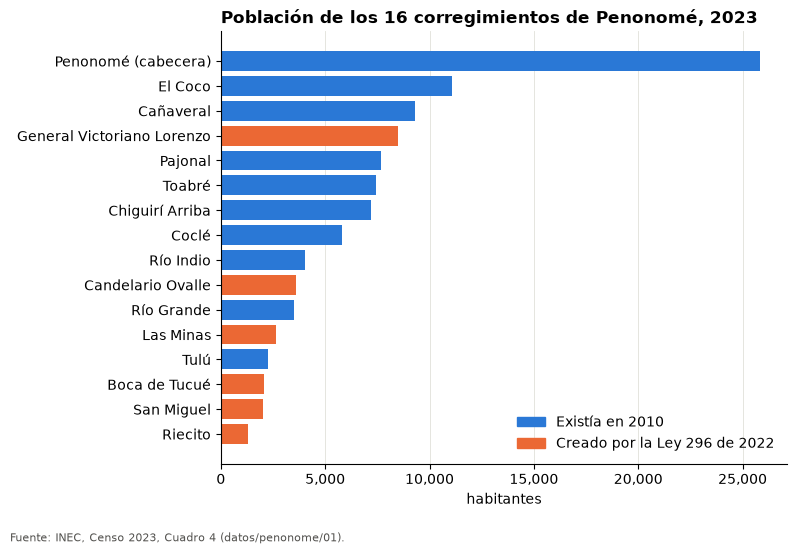

In [8]:
grandes = pob_2023[pob_2023 > 8000].sort_values(ascending=False)
print(grandes)
verificar("corregimientos con más de 8,000 habitantes", len(grandes), 4)

nuevos = set(crecimiento[crecimiento.isna()].index)
ordenada = pob_2023.sort_values()
colores = [an.NARANJA if nombre in nuevos else an.AZUL for nombre in ordenada.index]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(ordenada.index, ordenada.values, color=colores)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=an.AZUL, label="Existía en 2010"),
                   Patch(color=an.NARANJA, label="Creado por la Ley 296 de 2022")],
          frameon=False, loc="lower right")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
an.estilo_eje(ax, "Población de los 16 corregimientos de Penonomé, 2023", "habitantes", "",
              "INEC, Censo 2023, Cuadro 4 (datos/penonome/01).")
ax.grid(True, axis="x", color="#e1e0d9", linewidth=0.6)
ax.grid(False, axis="y")
plt.show()

**Clave:** una Serie es un arreglo con etiquetas. Las operaciones se alinean por índice y los huecos se vuelven `NaN`, lo que avisa de que un dato no es comparable en lugar de dar un número falso.

**Referencia:** [Unidad 35 — Serie Pandas](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u35-series-de-pandas.ipynb): creación, selección con `loc` e `iloc`, operaciones aritméticas, estadísticas descriptivas y gráfico de barras.

## 3. DataFrames: mercado laboral y Censo 2023

Un DataFrame es una tabla de columnas que comparten el índice ([Unidad 36](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u36-dataframes-de-pandas.ipynb)). La tabla 03 de la Encuesta de Mercado Laboral (EML) del INEC trae, para la República y Coclé, las personas activas, ocupadas y desocupadas en octubre de 2024 y septiembre de 2025.

In [9]:
eml = leer("03_eml_condicion_actividad.csv")
print(eml.shape, "->", eml["area"].unique().tolist())

cocle = eml[eml["area"] == "Coclé"].set_index("indicador")         # filtrado y nuevo índice
print(cocle[["oct2024_total", "sep2025_total"]])
print()
print("Tasa de desempleo de Coclé, sep-2025:", cocle.loc["Tasa de desempleo (%)", "sep2025_total"], "%")
print("Mujeres desocupadas, sep-2025       :", int(cocle.loc["Desocupada", "sep2025_mujeres"]))
verificar("tasa de desempleo publicada de Coclé, sep-2025", cocle.loc["Tasa de desempleo (%)", "sep2025_total"], 7.1)

(40, 8) -> ['República', 'Coclé', 'Coclé urbana', 'Coclé rural']
                            oct2024_total  sep2025_total
indicador                                               
Población 15+                    205705.0       207110.0
Económicamente activa            142040.0       143191.0
Tasa de participación (%)            69.1           69.1
Ocupada                          134009.0       133026.0
Desocupada                         8031.0        10165.0
Tasa de desempleo (%)                 5.7            7.1
Desempleo abierto                  5750.0         6525.0
Tasa desempleo abierto (%)            4.0            4.6
Desempleo oculto                   2281.0         3640.0
No económicamente activa          63665.0        63919.0

Tasa de desempleo de Coclé, sep-2025: 7.1 %
Mujeres desocupadas, sep-2025       : 6760
Correcto: tasa de desempleo publicada de Coclé, sep-2025


La tasa de desempleo es `desocupados / población activa * 100`. Recalcularla para las cuatro áreas y las dos fechas es una buena prueba de que la tabla se transcribió bien: con `pivot` (que se estudia a fondo en la semana 6) se obtiene una fila por área y una columna por indicador.

In [10]:
columnas = ["oct2024_total", "sep2025_total"]
filas = []
for periodo in columnas:
    tabla = eml.pivot(index="area", columns="indicador", values=periodo)
    calculada = (tabla["Desocupada"] / tabla["Económicamente activa"] * 100).round(1)
    filas.append(pd.DataFrame({"periodo": periodo[:7], "publicada": tabla["Tasa de desempleo (%)"], "calculada": calculada}))
tasas = pd.concat(filas)
tasas["diferencia"] = (tasas["calculada"] - tasas["publicada"]).round(1)
print(tasas)

verificar("las 8 tasas recalculadas coinciden con las publicadas (±0.1)", bool((tasas["diferencia"].abs() <= 0.1).all()), True)

              periodo  publicada  calculada  diferencia
area                                                   
Coclé         oct2024        5.7        5.7         0.0
Coclé rural   oct2024        5.2        5.2         0.0
Coclé urbana  oct2024        6.3        6.3         0.0
República     oct2024        9.7        9.7         0.0
Coclé         sep2025        7.1        7.1         0.0
Coclé rural   sep2025        5.8        5.8         0.0
Coclé urbana  sep2025        9.1        9.1         0.0
República     sep2025       10.4       10.4         0.0
Correcto: las 8 tasas recalculadas coinciden con las publicadas (±0.1)


El Censo 2023 (tabla 02) permite bajar al nivel de corregimiento. Se agrega una columna calculada, se ordena con `sort_values()` y se comprueba que los corregimientos sumen el total del distrito.

In [11]:
censo = tabla02[tabla02["nivel"] == "corregimiento"].set_index("area")
censo["tasa_desocupacion"] = (censo["desocupados"] / (censo["ocupados"] + censo["desocupados"]) * 100).round(1)
censo["pct_sin_internet"] = (censo["sin_internet"] / censo["viviendas"] * 100).round(1)

print(censo[["poblacion", "ocupados", "desocupados", "tasa_desocupacion", "pct_sin_internet"]]
      .sort_values("tasa_desocupacion", ascending=False).head(6))

distrito = tabla02[tabla02["nivel"] == "distrito"].iloc[0]
sumas = censo[["poblacion", "ocupados", "desocupados"]].sum()
tasa_distrito = round(distrito["desocupados"] / (distrito["ocupados"] + distrito["desocupados"]) * 100, 1)
print()
print("Tasa censal del distrito:", tasa_distrito, "%")

verificar("ocupados de los corregimientos = distrito", int(sumas["ocupados"]), int(distrito["ocupados"]))
verificar("desocupados de los corregimientos = distrito", int(sumas["desocupados"]), int(distrito["desocupados"]))
verificar("tasa censal de desocupación del distrito (%)", tasa_distrito, 6.3)

                            poblacion  ocupados  desocupados  \
area                                                           
Pajonal                          7678      2884          375   
General Victoriano Lorenzo       8496      3022          371   
Río Grande                       3505      1399          164   
Cañaveral                        9324      3632          364   
Penonomé (cabecera)             25836     11104          977   
Coclé                            5811      2089          159   

                            tasa_desocupacion  pct_sin_internet  
area                                                             
Pajonal                                  11.5              57.6  
General Victoriano Lorenzo               10.9              32.1  
Río Grande                               10.5              35.1  
Cañaveral                                 9.1              31.6  
Penonomé (cabecera)                       8.1              17.5  
Coclé                    

**Error común:** comparar el 6.3 % del Censo con el 5.7 % o el 7.1 % de la EML como si fueran la misma medida. El Censo pregunta a toda la población un solo día; la EML es una encuesta por muestra con otra definición de búsqueda de empleo. Se compara el orden de magnitud, no el número exacto.

**Clave:** con un DataFrame se filtra (`df[condicion]`), se cambia el índice (`set_index`), se seleccionan celdas (`loc`), se agregan columnas calculadas y se ordena (`sort_values`), siempre sobre la tabla completa y sin bucles.

**Referencia:** [Unidad 36 — Pandas DataFrame](../../../../01-python/semana-05/clase-2-modulos-y-pandas/u36-dataframes-de-pandas.ipynb): creación, índice y columnas, lectura de CSV, selección y filtrado.

## 4. Programación dinámica

### 4.1 El mejor tramo del PIB: subarreglo de suma máxima

La práctica en pareja de la [Unidad 32](../../../../01-python/semana-05/clase-1-programacion-dinamica-y-backtracking/u32-programacion-dinamica.ipynb) pide el tramo de valores consecutivos con la suma máxima. Aplicado a la variación anual del PIB de Coclé (millones de balboas, volumen encadenado), la pregunta es: **¿cuál fue el periodo seguido de mayor crecimiento acumulado?** La recurrencia ascendente `mejor_hasta = max(S[i], mejor_hasta + S[i])` lo resuelve en un solo recorrido; `an.maximum_subarray` además devuelve dónde empieza y termina el tramo. En el [notebook de la semana 4](s04-ordenamiento-greedy-divide-y-venceras.ipynb) el mismo problema se resolvió con dividir y vencerás sobre los meses de turismo.

In [12]:
pib = an.pib_anual()["PIB COCLÉ"]
cambios = pib.diff().dropna().round(1)            # variación de cada año frente al anterior
S = cambios.tolist()
anios = cambios.index.year.tolist()
print(dict(zip(anios, S)))

mejor, inicio, fin = an.maximum_subarray(S)
print(f"Mejor tramo: {anios[inicio]}-{anios[fin]}, suma {mejor:.1f} millones")

# Comprobación con fuerza bruta: probar todos los tramos (O(n^2))
fuerza_bruta = max(sum(S[i:j + 1]) for i in range(len(S)) for j in range(i, len(S)))
verificar("la recurrencia coincide con la fuerza bruta", round(mejor, 1), round(fuerza_bruta, 1))
verificar("suma del mejor tramo (millones de B/.)", round(mejor, 1), 721.1)
verificar("años del mejor tramo", (anios[inicio], anios[fin]), (2021, 2024))

{2019: -73.5, 2020: -429.2, 2021: 420.6, 2022: 114.1, 2023: 40.2, 2024: 146.2}
Mejor tramo: 2021-2024, suma 721.1 millones
Correcto: la recurrencia coincide con la fuerza bruta
Correcto: suma del mejor tramo (millones de B/.)
Correcto: años del mejor tramo


La lectura es directa: tras la caída de 2020 (-429.2 millones), Coclé encadenó cuatro años de crecimiento, de 2021 a 2024, que suman 721.1 millones. La suma supera la caída, por lo que en 2024 el PIB ya estaba por encima del nivel de 2019.

**Error común:** sumar las actividades del cuadro para obtener el total. El PIB está en volumen encadenado y la suma no da exacta (4.3 millones de diferencia en 2024, explicada por el INEC). Por eso aquí se usa la fila `PIB COCLÉ` tal como se publica.

### 4.2 Proyección del desempleo con memorización

La comparación con Colombia (`analisis-penonome.ipynb`) proyecta el desempleo de Coclé tras el sismo con un golpe que se reduce a la mitad cada cierto número de meses. Escrito como recurrencia, es un problema de programación dinámica del mismo tipo que Fibonacci:

- `G(0) = golpe` (puntos porcentuales que suma el sismo).
- `G(t) = G(t - 1) * 0.5 ** (1 / meses_media_vida)`.
- desempleo del mes `t` = línea base + `G(t)`.

`an.golpe_restante` guarda cada `G(t)` en un diccionario `memo`, como `fib_memo` en la práctica de la u32, y todas las llamadas de un escenario comparten esa tabla. La línea base es el 5.5 % de agosto de 2026 (INEC) y el golpe se mide en Colombia con diferencias en diferencias. Los factores de intensidad y de media vida son **supuestos** del estudio, no datos.

In [13]:
socio = leer("23_socioeconomico_colombia_vs_cocle.csv", an.COMPARACION)
fila = socio[(socio["area"] == "Coclé") & (socio["indicador"] == "desempleo_provincial") & (socio["fecha"] == "2026-08")]
linea_base = float(fila["valor"].iloc[0])

brecha = an.brecha_colombia()                     # afectadas menos control, por trimestre móvil
efecto = brecha.loc["jul-sep", "brecha"] - brecha.loc["abr-jun", "brecha"]
print(f"Línea base de Coclé: {linea_base} % | efecto medido en Colombia: {efecto:.2f} pp")

verificar("desempleo de Coclé en agosto de 2026 (%)", linea_base, 5.5)
verificar("efecto del sismo en Colombia (pp)", round(efecto, 2), 2.05)

Línea base de Coclé: 5.5 % | efecto medido en Colombia: 2.05 pp
Correcto: desempleo de Coclé en agosto de 2026 (%)
Correcto: efecto del sismo en Colombia (pp)


In [14]:
escenarios = {                                    # SUPUESTOS del estudio (factor de intensidad, meses de media vida)
    "Rápido (como Colombia nacional)": (0.5, 3),
    "Base": (1.0, 9),
    "Lento (norte rural, informal)": (1.5, 24),
}
meses = pd.date_range("2026-10-01", "2030-12-01", freq="MS")
proyeccion = pd.DataFrame(
    {nombre: an.proyectar_desempleo(linea_base, efecto * factor, vida, len(meses))
     for nombre, (factor, vida) in escenarios.items()},
    index=meses,
)
anual = proyeccion.groupby(proyeccion.index.year).mean().round(2)
print(anual)

# La tabla memo guarda un valor por mes: 51 meses, cada uno calculado una sola vez
memo = {0: efecto}
an.golpe_restante(len(meses) - 1, efecto, 9, memo)
print("Entradas en la tabla memo del escenario base:", len(memo))

publicada = leer("30_proyeccion_cocle_escenarios.csv", an.COMPARACION).set_index("Unnamed: 0")
verificar("la recurrencia reproduce datos/comparacion-colombia/30 (5 años x 3 escenarios)", anual.values.tolist(), publicada.values.tolist())
verificar("desempleo medio de 2026 en el escenario base (%)", anual.loc[2026, "Base"], 7.4)

      Rápido (como Colombia nacional)  Base  Lento (norte rural, informal)
2026                             6.33  7.40                           8.49
2027                             5.69  6.60                           7.92
2028                             5.51  5.94                           7.21
2029                             5.50  5.67                           6.71
2030                             5.50  5.57                           6.36
Entradas en la tabla memo del escenario base: 51
Correcto: la recurrencia reproduce datos/comparacion-colombia/30 (5 años x 3 escenarios)
Correcto: desempleo medio de 2026 en el escenario base (%)


**Clave:** la memorización convierte una recurrencia en una tabla que se llena una vez. Aquí la recursión es lineal, así que la ganancia no es de velocidad como en `fib1`, sino de reutilización: las 51 llamadas del escenario comparten la misma tabla, como `fib2`.

**Error común:** leer estos escenarios como datos. Son el resultado de un modelo con supuestos; el dato oficial posterior al sismo todavía no existe.

**Referencia:** [Unidad 32 — Programación dinámica](../../../../01-python/semana-05/clase-1-programacion-dinamica-y-backtracking/u32-programacion-dinamica.ipynb): memorización con diccionario (`fib2`, `fib_memo`) y subarreglo de suma máxima.

## 5. Retroceso: combinaciones de corregimientos

La cabecera tiene 25,836 habitantes. **¿Cuál es el menor número de corregimientos rurales que, juntos, reúnen al menos esa población, y cuáles son todas esas combinaciones?** Probar todos los subconjuntos de los otros 15 corregimientos son 2^15 = 32,768 casos. El retroceso de la [Unidad 33](../../../../01-python/semana-05/clase-1-programacion-dinamica-y-backtracking/u33-backtracking.ipynb) recorre el árbol de decisiones (incluir o no cada corregimiento) en profundidad y **poda** las ramas no prometedoras:

- si la suma actual más todo lo que queda por elegir no alcanza el objetivo;
- si la rama ya necesitaría más corregimientos que la mejor solución encontrada.

La función `promising` dentro de `an.combinaciones_minimas` cumple el mismo papel que en el problema de las N reinas.

In [15]:
import itertools

rurales = tabla01.drop("penonome_cabecera")
valores = rurales["pob_2023"].tolist()
objetivo = int(tabla01.loc["penonome_cabecera", "pob_2023"])

soluciones, nodos = an.combinaciones_minimas(valores, objetivo)
k = len(soluciones[0])
print(f"Objetivo: {objetivo:,} habitantes. Mínimo de corregimientos: {k}. Combinaciones: {len(soluciones)}")
print(f"Nodos visitados con poda: {nodos:,} de {2 ** len(valores):,} subconjuntos posibles")
print()
for combinacion in soluciones:
    nombres = [rurales["corregimiento"].iloc[i] for i in combinacion]
    print(f"{sum(valores[i] for i in combinacion):>6,}  " + ", ".join(nombres))

Objetivo: 25,836 habitantes. Mínimo de corregimientos: 3. Combinaciones: 10
Nodos visitados con poda: 335 de 32,768 subconjuntos posibles

26,199  Cañaveral, Coclé, El Coco
27,573  Cañaveral, Chiguirí Arriba, El Coco
28,066  Cañaveral, El Coco, Pajonal
27,828  Cañaveral, El Coco, Toabré
28,884  Cañaveral, El Coco, General Victoriano Lorenzo
25,927  Chiguirí Arriba, El Coco, Pajonal
26,745  Chiguirí Arriba, El Coco, General Victoriano Lorenzo
26,182  El Coco, Pajonal, Toabré
27,238  El Coco, Pajonal, General Victoriano Lorenzo
27,000  El Coco, Toabré, General Victoriano Lorenzo


In [16]:
# Comprobación por fuerza bruta con itertools: ninguna combinación de k - 1 llega y las de k coinciden
alcanza = lambda c: sum(valores[i] for i in c) >= objetivo
con_k = sorted(c for c in itertools.combinations(range(len(valores)), k) if alcanza(c))
con_menos = [c for c in itertools.combinations(range(len(valores)), k - 1) if alcanza(c)]

verificar("mínimo de corregimientos para igualar a la cabecera", k, 3)
verificar("número de combinaciones mínimas", len(soluciones), 10)
verificar("el retroceso encuentra las mismas combinaciones que la fuerza bruta", soluciones, con_k)
verificar("ninguna combinación de 2 corregimientos alcanza", con_menos, [])

Correcto: mínimo de corregimientos para igualar a la cabecera
Correcto: número de combinaciones mínimas
Correcto: el retroceso encuentra las mismas combinaciones que la fuerza bruta
Correcto: ninguna combinación de 2 corregimientos alcanza


Basta con tres corregimientos, y las diez combinaciones incluyen siempre a El Coco (11,064), el mayor de los rurales. La poda reduce la búsqueda a 335 nodos: ordenar los valores de mayor a menor hace que la primera solución aparezca pronto, y a partir de ahí el límite de tamaño corta casi todo el árbol.

**Error común:** guardar la lista `elegidos` sin copiarla. Como en `soluciones_n_reinas` de la u33, la lista se sigue modificando al retroceder; por eso la función guarda `tuple(sorted(elegidos))`.

**Referencia:** [Unidad 33 — Retroceso](../../../../01-python/semana-05/clase-1-programacion-dinamica-y-backtracking/u33-backtracking.ipynb): búsqueda en profundidad, función `promising`, poda y subconjuntos con suma objetivo.

## Conclusiones

- Módulos (u34): el código del proyecto quedó en un paquete con un módulo por etapa; los notebooks importan `penonome.analisis` y no repiten funciones.
- Series (u35): la población de Penonomé está muy concentrada (la cabecera es el 24.8 % del distrito) y la alineación por índice deja en `NaN` a los seis corregimientos nuevos, que no son comparables con 2010.
- DataFrames (u36): las ocho tasas de desempleo de la EML y los totales del Censo se recalculan desde sus componentes y coinciden con lo publicado.
- Programación dinámica (u32): el mejor tramo del PIB de Coclé es 2021-2024 (+721.1 millones), y la recurrencia memorizada reproduce exacto los escenarios de desempleo del estudio.
- Retroceso (u33): con poda, la búsqueda visita 335 nodos en lugar de 32,768 subconjuntos y halla las 10 combinaciones de tres corregimientos que igualan a la cabecera.

La semana 6 reorganiza estos datos en formato ordenado, los convierte en series temporales y cierra el proyecto con el análisis final.

[Proyecto](../../README.md) | [Anterior](s04-ordenamiento-greedy-divide-y-venceras.ipynb) | [Siguiente](s06-ordenacion-series-temporales.ipynb)